In [1]:
import sys;
sys.path.append('/home/ashesh.ashesh/code/Disentangle')

In [2]:
import os
from disentangle.core.tiff_reader import load_tiff, save_tiff


def convert_to_kth_data(fpath):
    """
    In case we have the full prediction tiff file, we need to convert it to kth data format. one prediction per file.
    """
    "/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D21-M3-S0-L8_6_1.tif"
    fname = os.path.basename(fpath)
    fdir = os.path.join(os.path.dirname(fpath), "kth_{k}")
    new_fpath_schema = os.path.join(fdir, fname)

    data = load_tiff(fpath).squeeze()
    assert len(data.shape) in [3, 4]
    if len(data.shape) == 3:
        fpath = new_fpath_schema.format(k=0)
        os.makedirs(os.path.dirname(fpath), exist_ok=True)
        print("Saving to", fpath, "shape", data.shape)
        save_tiff(fpath, data)
    elif len(data.shape) == 4:
        for k in range(data.shape[0]):
            fpath = new_fpath_schema.format(k=k)
            os.makedirs(os.path.dirname(fpath), exist_ok=True)
            print("Saving to", fpath, "shape", data[k].shape)
            save_tiff(fpath, data[k])
    elif len(data.shape) == 5:
        assert data.shape[0] == 1
        for k in range(data.shape[1]):
            fpath = new_fpath_schema.format(k=k)
            os.makedirs(os.path.dirname(fpath), exist_ok=True)
            print("Saving to", fpath, "shape", data[0, k][None].shape)
            save_tiff(fpath, data[0, k][None])
    elif len(data.shape) == 6:
        # CARE 3D
        assert data.shape[0] == 1
        assert data.shape[1] == 1
        data = data[0, 0]
        for k in range(data.shape[0]):
            fpath = new_fpath_schema.format(k=k)
            os.makedirs(os.path.dirname(fpath), exist_ok=True)
            print("Saving to", fpath, "shape", data[k].shape)
            save_tiff(fpath, data[k])


In [3]:
# 2501/D18-M3-S0-L8/5
# 2411/D30-M3-S0-L8/26
# convert_to_kth_data('/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/pred_training_disentangle_2506_D30-M3-S0-L8_5_1.tif')
# cropped_Input_2404_D21-M3-S0-L8_6_K0_300-300-800-600

In [4]:
from disentangle.data_loader.train_val_data import get_train_val_data
from disentangle.config_utils import load_config
from disentangle.scripts.evaluate import get_data_dir
from disentangle.core.data_split_type import DataSplitType
from disentangle.core.tiff_reader import save_tiff, load_tiff
import os

gt_root_dir = "/group/jug/ashesh/kth_data"
pred_rootdir = "/group/jug/ashesh/training/disentangle"
output_data_dir = "/group/jug/ashesh/naturemethods/two_splitting/"
KTH_SAMPLE = 0


def sample_subdir(k):
    return "kth{}".format(k)


def get_gt_dir(dtype):
    gt_dir = os.path.join(gt_root_dir, dtype)
    gt_dir = os.path.join(gt_dir, sample_subdir(KTH_SAMPLE))
    return gt_dir


def get_kth_gt(val_data):
    if hasattr(val_data, "_data"):
        gt_data = val_data._data[KTH_SAMPLE][0]
    elif isinstance(val_data, list) and isinstance(val_data[0], tuple) and isinstance(val_data[0][1], str):
        assert len(val_data) == 1
        gt_data = val_data[0][0][KTH_SAMPLE]
    elif len(val_data.shape) == 4:
        gt_data = val_data[KTH_SAMPLE]
    elif len(val_data.shape) == 5:
        assert val_data.shape[0] == 1
        gt_data = val_data[0, KTH_SAMPLE]
    return gt_data


full_frame_pred_dirs = {
    # daozheng
    # '2501/D18-M3-S0-L8/1': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2501_D18-M3-S0-L8_1_1.tif',
    # '2501/D18-M3-S0-L8/5': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2501_D18-M3-S0-L8_5_1.tif',
    # '2501/D18-M3-S0-L8/4': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2501_D18-M3-S0-L8_4_1.tif',
    # '2501/D18-M3-S0-L8/6': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2501_D18-M3-S0-L8_6_1.tif',
    # '2501/D18-M3-S0-L8/2': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2501_D18-M3-S0-L8_2_1.tif',
    # '2501/D18-M3-S0-L8/3': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2501_D18-M3-S0-L8_3_1.tif',
    # pavia
    # '2408/D24-M3-S0-L8/16': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_16_1.tif',
    # '2408/D24-M3-S0-L8/13': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_13_1.tif',
    # '2408/D24-M3-S0-L8/15': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_15_1.tif',
    # '2408/D24-M3-S0-L8/14': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_14_1.tif',
    # '2408/D24-M3-S0-L8/13': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_13_1.tif',
    # '2408/D24-M3-S0-L8/12': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_12_1.tif',
    # '2408/D24-M3-S0-L8/11': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_11_1.tif',
    #   '2408/D24-M3-S0-L8/8': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_8_1.tif'
    #   '2408/D24-M3-S0-L8/10': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_10_1.tif',
    # '2408/D24-M3-S0-L8/5': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_5_1.tif',
    # '2408/D24-M3-S0-L8/6': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_6_1.tif'
    #   '2408/D24-M3-S0-L8/9': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_9_1.tif',
    # '2408/D24-M3-S0-L8/16': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D24-M3-S0-L8_16_1.tif',
    # '2408/D29-M3-S0-L8/24': f'/group/jug/ashesh/data/paper_stats/Test_P64_G7-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D29-M3-S0-L8_24_1.tif'
    "2404/D21-M3-S0-L8/6": f"/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D21-M3-S0-L8_6_1.tif",
    # '2501/D25-M3-S0-L8/3': '/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_0/pred_training_disentangle_2501_D25-M3-S0-L8_3_1.tif',
    # '2408/D29-M3-S0-L8/22': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2408_D29-M3-S0-L8_22_1.tif'
    # '2506/D29-M3-S0-L8/3': f'/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2506_D29-M3-S0-L8_3_1.tif'
    # '2408/D19-M3-S0-L8/11':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/pred_training_disentangle_2408_D19-M3-S0-L8_11_1.tif'
    # '2408/D12-M3-S0-L8/3': '/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/pred_training_disentangle_2408_D12-M3-S0-L8_3_1.tif',
    # '2507/D33-M3-S0-L8/22' : f'/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D33-M3-S0-L8_22_1.tif',
    # '2507/D33-M3-S0-L8/19':f'/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_{KTH_SAMPLE}/pred_training_disentangle_2507_D33-M3-S0-L8_19_1.tif',
    # '2507/D33-M3-S0-L8/21':'/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/kth_6/pred_training_disentangle_2507_D33-M3-S0-L8_21_1.tif'
    # '2404/D25-M3-S0-L8/97': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D25-M3-S0-L8_97_1.tif',
    # '2404/D25-M3-S0-L8/111': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D25-M3-S0-L8_111_1.tif',
    # '2405/D18-M3-S0-L8/13': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2405_D18-M3-S0-L8_13_1.tif',
    # '2405/D18-M3-S0-L8/14': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2405_D18-M3-S0-L8_14_1.tif',
    # '2404/D19-M3-S0-L8/5' : f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk16_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D19-M3-S0-L8_5_1.tif',
    # '2404/D25-M3-S0-L8/120': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D25-M3-S0-L8_120_1.tif',
    # '2404/D25-M3-S0-L8/125': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D25-M3-S0-L8_125_1.tif',
    # '2404/D25-M3-S0-L8/139': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D25-M3-S0-L8_139_1.tif',
    # '2404/D25-M3-S0-L8/143': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D25-M3-S0-L8_143_1.tif',
    # '2405/D18-M3-S0-L8/15': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2405_D18-M3-S0-L8_15_1.tif',
    # '2405/D18-M3-S0-L8/10': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2405_D18-M3-S0-L8_10_1.tif',
    # '2405/D18-M3-S0-L8/11': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2405_D18-M3-S0-L8_11_1.tif',
    # '2405/D18-M3-S0-L8/12': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2405_D18-M3-S0-L8_12_1.tif',
    # '2404/D17-M3-S0-L8/4': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D17-M3-S0-L8_4_1.tif',
    # '2404/D21-M3-S0-L8/1': f'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_{KTH_SAMPLE}/pred_disentangle_2404_D21-M3-S0-L8_1_1.tif',
}


crops_pred_dirs = {
    # '2404/D21-M3-S0-L8/6':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D21-M3-S0-L8_6.pkl',
    # '2404/D25-M3-S0-L8/97':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_97.pkl',
    # '2404/D25-M3-S0-L8/120':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_120.pkl',
    # '2404/D25-M3-S0-L8/111':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_111.pkl',
    # '2404/D25-M3-S0-L8/125':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_125.pkl',
    # '2404/D25-M3-S0-L8/139':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_139.pkl',
    # '2404/D25-M3-S0-L8/143':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D25-M3-S0-L8_143.pkl',
    # '2405/D18-M3-S0-L8/13':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_13.pkl',
    # '2405/D18-M3-S0-L8/14':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_14.pkl',
    # '2405/D18-M3-S0-L8/15':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_15.pkl',
    # '2405/D18-M3-S0-L8/10':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_10.pkl',
    # '2405/D18-M3-S0-L8/11':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_11.pkl',
    # '2405/D18-M3-S0-L8/12':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2405_D18-M3-S0-L8_12.pkl',
    # '2404/D17-M3-S0-L8/4':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D17-M3-S0-L8_4.pkl',
    # '2404/D21-M3-S0-L8/1':'/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_disentangle_2404_D21-M3-S0-L8_1.pkl',
}

resolution_nm_dict = {
    "2404/D21-M3-S0-L8/6": 110,
    "2506/D29-M3-S0-L8/3": 285,
    "2408/D29-M3-S0-L8/24": 285,
    "2408/D19-M3-S0-L8/11": 42,
    "2408/D12-M3-S0-L8/3": 37,
    "2408/D24-M3-S0-L8/8": 68,
    "2408/D24-M3-S0-L8/10": 68,
    "2408/D24-M3-S0-L8/9": 68,
    "2408/D24-M3-S0-L8/11": 68,
    "2408/D24-M3-S0-L8/12": 68,
    "2408/D24-M3-S0-L8/13": 68,
    "2408/D24-M3-S0-L8/14": 68,
    "2408/D24-M3-S0-L8/15": 68,
    "2408/D24-M3-S0-L8/16": 68,
    "2501/D25-M3-S0-L8/3": 285,
    "2501/D18-M3-S0-L8/1": 270,
    "2501/D18-M3-S0-L8/5": 270,
    "2501/D18-M3-S0-L8/4": 270,
    "2501/D18-M3-S0-L8/6": 270,
    "2501/D18-M3-S0-L8/2": 270,
    "2501/D18-M3-S0-L8/3": 270,
}

### Fetch the kth frame data and store it for fast access

In [5]:
for model_dir, pred_fpath in full_frame_pred_dirs.items():
    dtype = model_dir.split("/")[1].split("-")[0]
    gt_dir = get_gt_dir(dtype)

    if not os.path.exists(gt_dir):
        print("No such dir {}. Creating it".format(gt_dir))
        os.makedirs(gt_dir, exist_ok=True)

    gt_fpath = os.path.join(gt_dir, "gt_for_" + os.path.basename(pred_fpath))
    if not os.path.exists(gt_fpath):
        print("GT data is not present at {}. Creating it".format(gt_fpath))
        # loading directory.
        config = load_config(os.path.join(pred_rootdir, model_dir, "config.pkl"))
        val_data = get_train_val_data(
            config.data,
            get_data_dir(int(dtype[1:])),
            DataSplitType.Test,
            val_fraction=config.training.val_fraction,
            test_fraction=config.training.test_fraction,
        )

        kth_gt = get_kth_gt(val_data)
        save_tiff(gt_fpath, kth_gt)


In [6]:
gt_fpath

'/group/jug/ashesh/kth_data/D21/kth0/gt_for_pred_disentangle_2404_D21-M3-S0-L8_6_1.tif'

In [7]:
from disentangle.core.tiff_reader import load_tiff
# load_tiff('/group/jug/ashesh/kth_data/D33/kth0/gt_for_pred_training_disentangle_2507_D33-M3-S0-L8_22_1.tif').shape


In [8]:
full_frame_pred_dirs

{'2404/D21-M3-S0-L8/6': '/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk8_F/kth_0/pred_disentangle_2404_D21-M3-S0-L8_6_1.tif'}

In [9]:
# dtype = key.split('/')[1].split('-')[0]
# config = load_config(os.path.join(pred_rootdir, key, 'config.pkl'))
# val_data = get_train_val_data(config.data, get_data_dir(int(dtype[1:])), DataSplitType.Test,
#         val_fraction=config.training.val_fraction,
#         test_fraction=config.training.test_fraction)
# kth_gt = get_kth_gt(val_data)

### Loading data

In [10]:
from disentangle.core.tiff_reader import load_tiff
from tqdm import tqdm

gt_pred_dict = {}
for model_dir, pred_fpath in tqdm(full_frame_pred_dirs.items()):
    dtype = model_dir.split("/")[1].split("-")[0]
    gt_dir = get_gt_dir(dtype)
    gt_fpath = os.path.join(gt_dir, "gt_for_" + os.path.basename(pred_fpath))
    kth_gt = load_tiff(gt_fpath)
    kth_pred = load_tiff(pred_fpath)
    if len(kth_gt.squeeze().shape) == 4:
        # this is 3D data.
        kth_gt = kth_gt.squeeze()
        z_idx = kth_gt.shape[0] // 2
        print("Taking z_idx", z_idx)
        kth_gt = kth_gt[z_idx]
        kth_pred = kth_pred.squeeze()[z_idx]

    gt_pred_dict[model_dir] = (kth_gt, kth_pred)


100%|██████████| 1/1 [00:00<00:00, 39.12it/s]


In [11]:
# https://www.notion.so/Evaluating-2-channel-results-281cea8bb51c47ccadd50a389614100f?pvs=4

keys = [
    '2404/D21-M3-S0-L8/6'
    # '2408/D24-M3-S0-L8/16'
    #  '2408/D12-M3-S0-L8/3'
    # "2506/D29-M3-S0-L8/3"
    # '2404/D21-M3-S0-L8/6',
    # '2408/D24-M3-S0-L8/6'
    # '2408/D19-M3-S0-L8/11'
    # '2408/D29-M3-S0-L8/22', #=> kth = 0
    # '2404/D25-M3-S0-L8/97', # => kth = 0
    # '2404/D25-M3-S0-L8/111', # => kth = 0
    # '2405/D18-M3-S0-L8/13', # => kth = 0
    # '2405/D18-M3-S0-L8/14', # => kth = 0
    # '2405/D19-M3-S0-L8/5',
    # '2405/D18-M3-S0-L8/15',
    # '2405/D18-M3-S0-L8/10',
    # '2405/D18-M3-S0-L8/11',
    # '2405/D18-M3-S0-L8/12',
    # '2408/D29-M3-S0-L8/24'
    # '2408/D24-M3-S0-L8/8'
    # '2408/D24-M3-S0-L8/10'
    # '2408/D24-M3-S0-L8/9'
    # '2408/D24-M3-S0-L8/11'
    # '2408/D24-M3-S0-L8/12'
    # '2408/D24-M3-S0-L8/13'
    # '2408/D24-M3-S0-L8/14'
    # '2408/D24-M3-S0-L8/15'
    # '2408/D24-M3-S0-L8/16'
    # '2501/D25-M3-S0-L8/3'
    # '2501/D18-M3-S0-L8/1'
    # '2501/D18-M3-S0-L8/5'
    # '2501/D18-M3-S0-L8/4'
    # '2501/D18-M3-S0-L8/6'
    # '2501/D18-M3-S0-L8/2'
    # '2501/D18-M3-S0-L8/3'
]

In [12]:
import matplotlib.pyplot as plt
from splitting_notebooks_utils import get_input

key = keys[-1]
print(key)

2404/D21-M3-S0-L8/6


In [13]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import pandas as pd

# 5x10 grid for the input. 2x10 grid for the two targets and predictions.


def get_cropped_img(inp, hfac, hs=None, ws=None, wN=None, extra_h=0, extra_w=0):
    if wN is None:
        wN = inp.shape[1]

    if ws is None:
        ws = (inp.shape[1] - wN) // 2
    else:
        assert ws + wN < inp.shape[1], f"Invalid ws for the input. ws = {ws}, wN = {wN}, inp.shape = {inp.shape}"

    hN = int(wN * hfac)
    if hs is None:
        hs = (inp.shape[0] - hN) // 2
    else:
        assert hs + hN < inp.shape[0], f"Invalid hs for the input. hs = {hs}, hN = {hN}, inp.shape = {inp.shape}"

    coords = (hs - extra_h // 2, ws - extra_w // 2, hN + extra_h // 2, wN + extra_w // 2)
    return inp[hs - extra_h // 2 : hs + hN + extra_h // 2, ws - extra_w // 2 : ws + wN + extra_w // 2], coords


def find_most_interesting_box(inp_crop, channel_h_factor):
    """
    Returns hs, the start of the box
    """
    boxH = int(np.ceil(channel_h_factor * inp_crop.shape[0]))
    idx = np.argmax(pd.Series(inp_crop.std(axis=1)).rolling(window=boxH).mean().iloc[boxH:].values)
    return idx

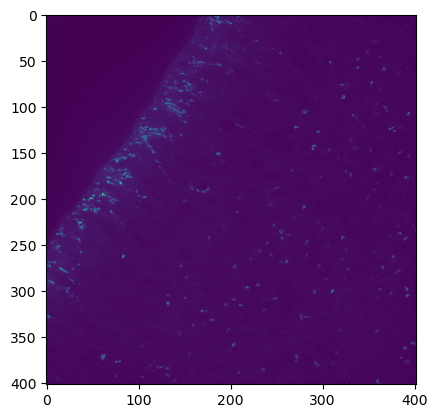

In [14]:
plt.imshow(gt_pred_dict[key][0][::4, ::4, 0])

In [15]:
import numpy as np
input_h_factor = 0.75
wN = 800
ws = 300
hs = 300

tar_h_factor = 0.75
tar_wN = 400
# input_h_factor = 0.75
# # nicola
# wN = 700
# tar_wN = 300
# tar_h_factor = 0.75

# dao
# wN = 800
# tar_wN = 400
# tar_h_factor = 0.75

# expansion
# input_h_factor = 0.75
# wN = 1100
# tar_wN = 800
# tar_h_factor = 0.75

# pavia
# input_h_factor = 1.5
# wN = 900
# tar_wN = 700
# tar_h_factor = 1.5

# Target crop
# tar_h_factor = 0.75
tar_hN = int(tar_h_factor * tar_wN)

savefig = True

if savefig is False:
    hs = np.random.randint(0, gt_pred_dict[key][0].shape[0] - int(wN * input_h_factor))
    ws = np.random.randint(0, gt_pred_dict[key][0].shape[1] - wN)
    print("ws", ws, "hs", hs)

# D29
# ws = 591
# hs = 226


# ws = 300
# hs = 300

In [16]:
# ws = 1100
# hs = 10

Real input
/group/jug/ashesh/naturemethods/two_splitting/cropped_Input_2404_D21-M3-S0-L8_6_K0_300-300-800-600.svg


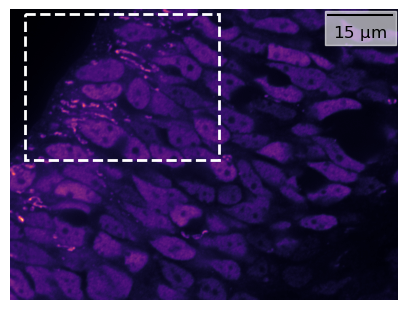

In [24]:
from matplotlib_scalebar.scalebar import ScaleBar

# Input crop
_, ax_inp = plt.subplots(figsize=(5, 5))

key = keys[0]
gt, pred = gt_pred_dict[key]
gt = gt.squeeze()
pred = pred.squeeze()
inp = get_input(gt, pred.shape[-1], None, None)[0]
inp_crop, input_coordinates = get_cropped_img(inp, input_h_factor, wN=wN, ws=ws, hs=hs)
ax_inp.imshow(inp_crop, cmap="magma")

if key in resolution_nm_dict:
    scalebar = ScaleBar(
        resolution_nm_dict[key],
        "nm",
        # length_fraction=0.1,
        box_alpha=0.6,
        frameon=True,
        location="upper right",
        font_properties={"size": 12},
    )

    ax_inp.add_artist(scalebar)

if savefig:
    ax_inp.axis("off")


# =============================================
# Set the top-left location
tar_rel_hs = 10
tar_rel_ws = 30
relative_coordinates = (tar_rel_hs, tar_rel_ws, tar_hN, tar_wN)
assert tar_rel_hs + tar_hN < inp_crop.shape[0], (
    f"Invalid tar_rel_hs for the input. tar_rel_hs = {tar_rel_hs}, tar_hN = {tar_hN}, inp_crop.shape = {inp_crop.shape}"
)
assert tar_rel_ws + tar_wN < inp_crop.shape[1], (
    f"Invalid tar_rel_ws for the input. tar_rel_ws = {tar_rel_ws}, tar_wN = {tar_wN}, inp_crop.shape = {inp_crop.shape}"
)

rect = patches.Rectangle(
    (relative_coordinates[1], relative_coordinates[0]),
    relative_coordinates[3],
    relative_coordinates[2],
    linewidth=2,
    edgecolor="w",
    facecolor="none",
    linestyle="--",
)
ax_inp.add_patch(rect)

if savefig:
    # filename should contain all cropping information
    fname = "cropped_Input_{}_K{}_{}-{}-{}-{}.svg".format(
        key.replace("/", "_"),
        KTH_SAMPLE,
        input_coordinates[1],
        input_coordinates[0],
        input_coordinates[3],
        input_coordinates[2],
    )

    fpath = os.path.join(output_data_dir, fname)
    print(fpath)
    plt.savefig(fpath, dpi=100, bbox_inches="tight")


/group/jug/ashesh/naturemethods/two_splitting/cropped_TarPred_2404_D21-M3-S0-L8_6_K0_310-330-300-400.png


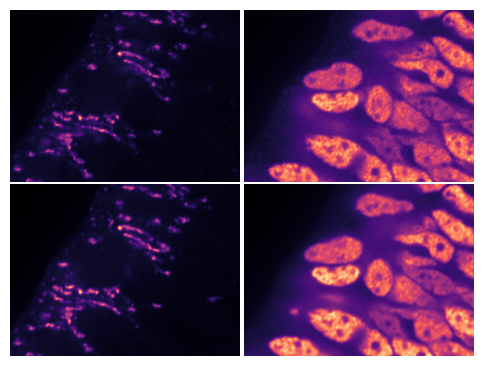

In [18]:
ncols = 2
nrows = 2
img_sz = 3
_, ax = plt.subplots(figsize=(ncols * img_sz, nrows * img_sz * tar_h_factor), ncols=ncols, nrows=nrows)

tar_hs = tar_rel_hs + input_coordinates[0]
tar_ws = tar_rel_ws + input_coordinates[1]
gt_crop = gt[tar_hs : tar_hs + tar_hN, tar_ws : tar_ws + tar_wN]
pred_crop = pred[tar_hs : tar_hs + tar_hN, tar_ws : tar_ws + tar_wN]
for i in range(ncols):
    vmin = np.quantile(gt_crop[..., i], 0.001)
    vmax = np.quantile(gt_crop[..., i], 0.999)
    ax[0, i].imshow(gt_crop[..., i], cmap="magma")#, vmin=vmin, vmax=vmax)
    ax[1, i].imshow(pred_crop[..., i], cmap="magma")#, vmin=vmin, vmax=vmax)
    ax[0, i].axis("off")
    ax[1, i].axis("off")

# reduce the space between the subplots
plt.subplots_adjust(wspace=0.01, hspace=0.01)

if savefig:
    # filename should contain all cropping information
    fname = "cropped_TarPred_{}_K{}_{}-{}-{}-{}.png".format(
        key.replace("/", "_"), KTH_SAMPLE, tar_hs, tar_ws, tar_hN, tar_wN
    )
    fpath = os.path.join(output_data_dir, fname)
    print(fpath)
    plt.savefig(fpath, dpi=100, bbox_inches="tight")

In [19]:
fpath = "/group/jug/ashesh/data/paper_stats/Test_P64_G32_M50_Sk0/stats_training_disentangle_2501_D18-M3-S0-L8_6.pkl"
import pickle

with open(fpath, "rb") as f:
    data = pickle.load(f)
data


def ssim_str(ssim_tmp):
    return f"{np.round(ssim_tmp[0], 3):.3f}+-{np.round(ssim_tmp[1], 3):.3f}"


def psnr_str(psnr_tmp):
    return f"{np.round(psnr_tmp[0], 2)}+-{np.round(psnr_tmp[1], 3)}"


print("PSNR on Highres", "\t".join([psnr_str(psnr_tmp) for psnr_tmp in data["rangeinvpsnr"]]))
print("MicroSSIM on Highres", "\t".join([ssim_str(ssim) for ssim in data["microssim"]]))
print("MicroS3IM on Highres", "\t".join([ssim_str(ssim) for ssim in data["ms3im"]]))
print("SSIM on Highres", "\t".join([ssim_str(ssim) for ssim in data["ssim"]]))
print("MSSSIM on Highres", "\t".join([ssim_str(ssim) for ssim in data["msssim"]]))


PSNR on Highres 43.71+-0.89	44.87+-1.461
MicroSSIM on Highres 0.993+-0.001	0.993+-0.001
MicroS3IM on Highres 0.995+-0.001	0.995+-0.001
SSIM on Highres 0.993+-0.001	0.993+-0.001
MSSSIM on Highres 0.995+-0.001	0.995+-0.001


In [21]:
from disentangle.core.tiff_reader import load_tiff

data = load_tiff(
    "/group/jug/ashesh/data/paper_stats/Test_P64_G3-32-32_M50_Sk0/pred_training_disentangle_2507_D32-M3-S0-L0_5_1.tif"
)

In [ ]:
import matplotlib.pyplot as plt

_, ax = plt.subplots(figsize=(12, 4), ncols=3)
for i in range(3):
    ax[i].imshow(data[0, 0, 3, ..., i], cmap="magma")